In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
from xgboost import XGBClassifier
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from datetime import datetime

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score

# from titanic_XGBoost import *

In [2]:
plt.rcParams.update({
    'font.size': 14,             # 所有字体的基准大小
    'axes.titlesize': 16,        # 子图标题（ax.set_title）
    'axes.labelsize': 13,        # x/y轴标签（ax.set_xlabel / set_ylabel）
    'xtick.labelsize': 13,       # x轴刻度字体
    'ytick.labelsize': 13,       # y轴刻度字体
    'legend.fontsize': 12,       # 图例字体
    'figure.titlesize': 20      # fig.suptitle 总标题字体
})

In [3]:
path = '/Users/eta/.cache/kagglehub/competitions/spaceship-titanic'
dataset = pd.read_csv(path + '/train.csv')

---

In [4]:
def getData(dataset: pd.DataFrame, istest=False):
    dataset_df = dataset.copy()
    # creat the new feature
    dataset_df['PassengerId'] = [int(i[:4]) for i in dataset_df['PassengerId']]
    dataset_df[["Deck", "Cabin_num", "Side"]] = dataset_df["Cabin"].str.split("/", expand=True)
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].fillna('0')
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].astype(int)

    # for Age: replace the nan with the mean value.
    dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

    # for bill: replace the nan with zero value. 
    for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)

    dataset_df['Cost'] = dataset_df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1)

    # for category: using the one-hot encoding.
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

    # one-hot encoding:
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[name].unique()), dataset_df[name].unique())
        for key in dataset_df[name].unique():
            dataset_df[f'{name}_{key}'] = 0
            dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1

        dataset_df.drop(columns=[name], inplace=True)

    # dorp the meanless columns
    dataset_df = dataset_df.drop(['Cabin', 'Name'], axis=1)

    if istest:
        return dataset_df
    else:
        dataset_x = dataset_df.drop(columns=['Transported'])
        dataset_y = dataset_df['Transported']

        return dataset_x, dataset_y

### XGBoost

In [5]:
dataset_x, dataset_y = getData(dataset)

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
#     stratify=dataset_y
)

print(x_train_df.shape)
x_train = np.array(x_train_df)
y_train = np.array(y_train_df)
x_val = np.array(x_val_df)
y_val = np.array(y_val_df)

(6954, 35)


In [6]:
X_train = np.asarray(x_train, dtype=np.float32)
X_val = np.asarray(x_val, dtype=np.float32)

Y_train = np.asarray(y_train, dtype=int).ravel()
Y_val = np.asarray(y_val, dtype=int).ravel()

In [90]:
xgboost = XGBClassifier(
    objective="binary:logistic",

    n_estimators=20000,
    learning_rate=0.006,
    max_depth=5,

    # Regularization
    reg_lambda=3.0,
    reg_alpha=0.0,
    gamma=0.0,
    min_child_weight=3,

    # Random sampling
    subsample=0.9,
    colsample_bytree=0.9,

    # Training
    tree_method="hist",
    eval_metric=["error", "logloss"],
    early_stopping_rounds=100,

    random_state=42,
    n_jobs=-1
)

In [91]:
xgboost.fit(X_train, Y_train, eval_set=[(X_train, Y_train), (X_val, Y_val)], verbose=False)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])","['error', 'logloss']"
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [92]:
history = xgboost.evals_result()

train_history = history["validation_0"]
val_history = history["validation_1"]

n_rounds = len(train_history["logloss"])
rounds = np.arange(n_rounds)

xgboost.log = {
    "train_acc": np.column_stack([
        rounds,
        1 - np.array(train_history["error"])
    ]).tolist(),

    "val_acc": np.column_stack([
        rounds,
        1 - np.array(val_history["error"])
    ]).tolist(),

    "train_loss": np.column_stack([
        rounds,
        np.array(train_history["logloss"])
    ]).tolist(),

    "val_loss": np.column_stack([
        rounds,
        np.array(val_history["logloss"])
    ]).tolist()
}

val_score_list = np.array(xgboost.log["val_acc"])
train_score_list = np.array(xgboost.log["train_acc"])

val_loss = np.array(xgboost.log["val_loss"])
train_loss = np.array(xgboost.log["train_loss"])

best_iteration = xgboost.best_iteration

train_pred = xgboost.predict(X_train)
val_pred = xgboost.predict(X_val)

print("Best iteration:", best_iteration)
print("Best validation logloss:", xgboost.best_score)

print("Train accuracy:", accuracy_score(Y_train, train_pred))
print("Val accuracy:", accuracy_score(Y_val, val_pred))

print("Maximum validation accuracy:", val_score_list[:, 1].max())
print("Iteration of maximum val accuracy:",
      int(val_score_list[np.argmax(val_score_list[:, 1]), 0]))

Best iteration: 2610
Best validation logloss: 0.39112106860415685
Train accuracy: 0.8734541271210814
Val accuracy: 0.8039102932719954
Maximum validation accuracy: 0.80448533640023
Iteration of maximum val accuracy: 2596


In [93]:
0.3917525408227455
0.394950060963003
0.39139678586045973
0.39112106860415685

0.39112106860415685

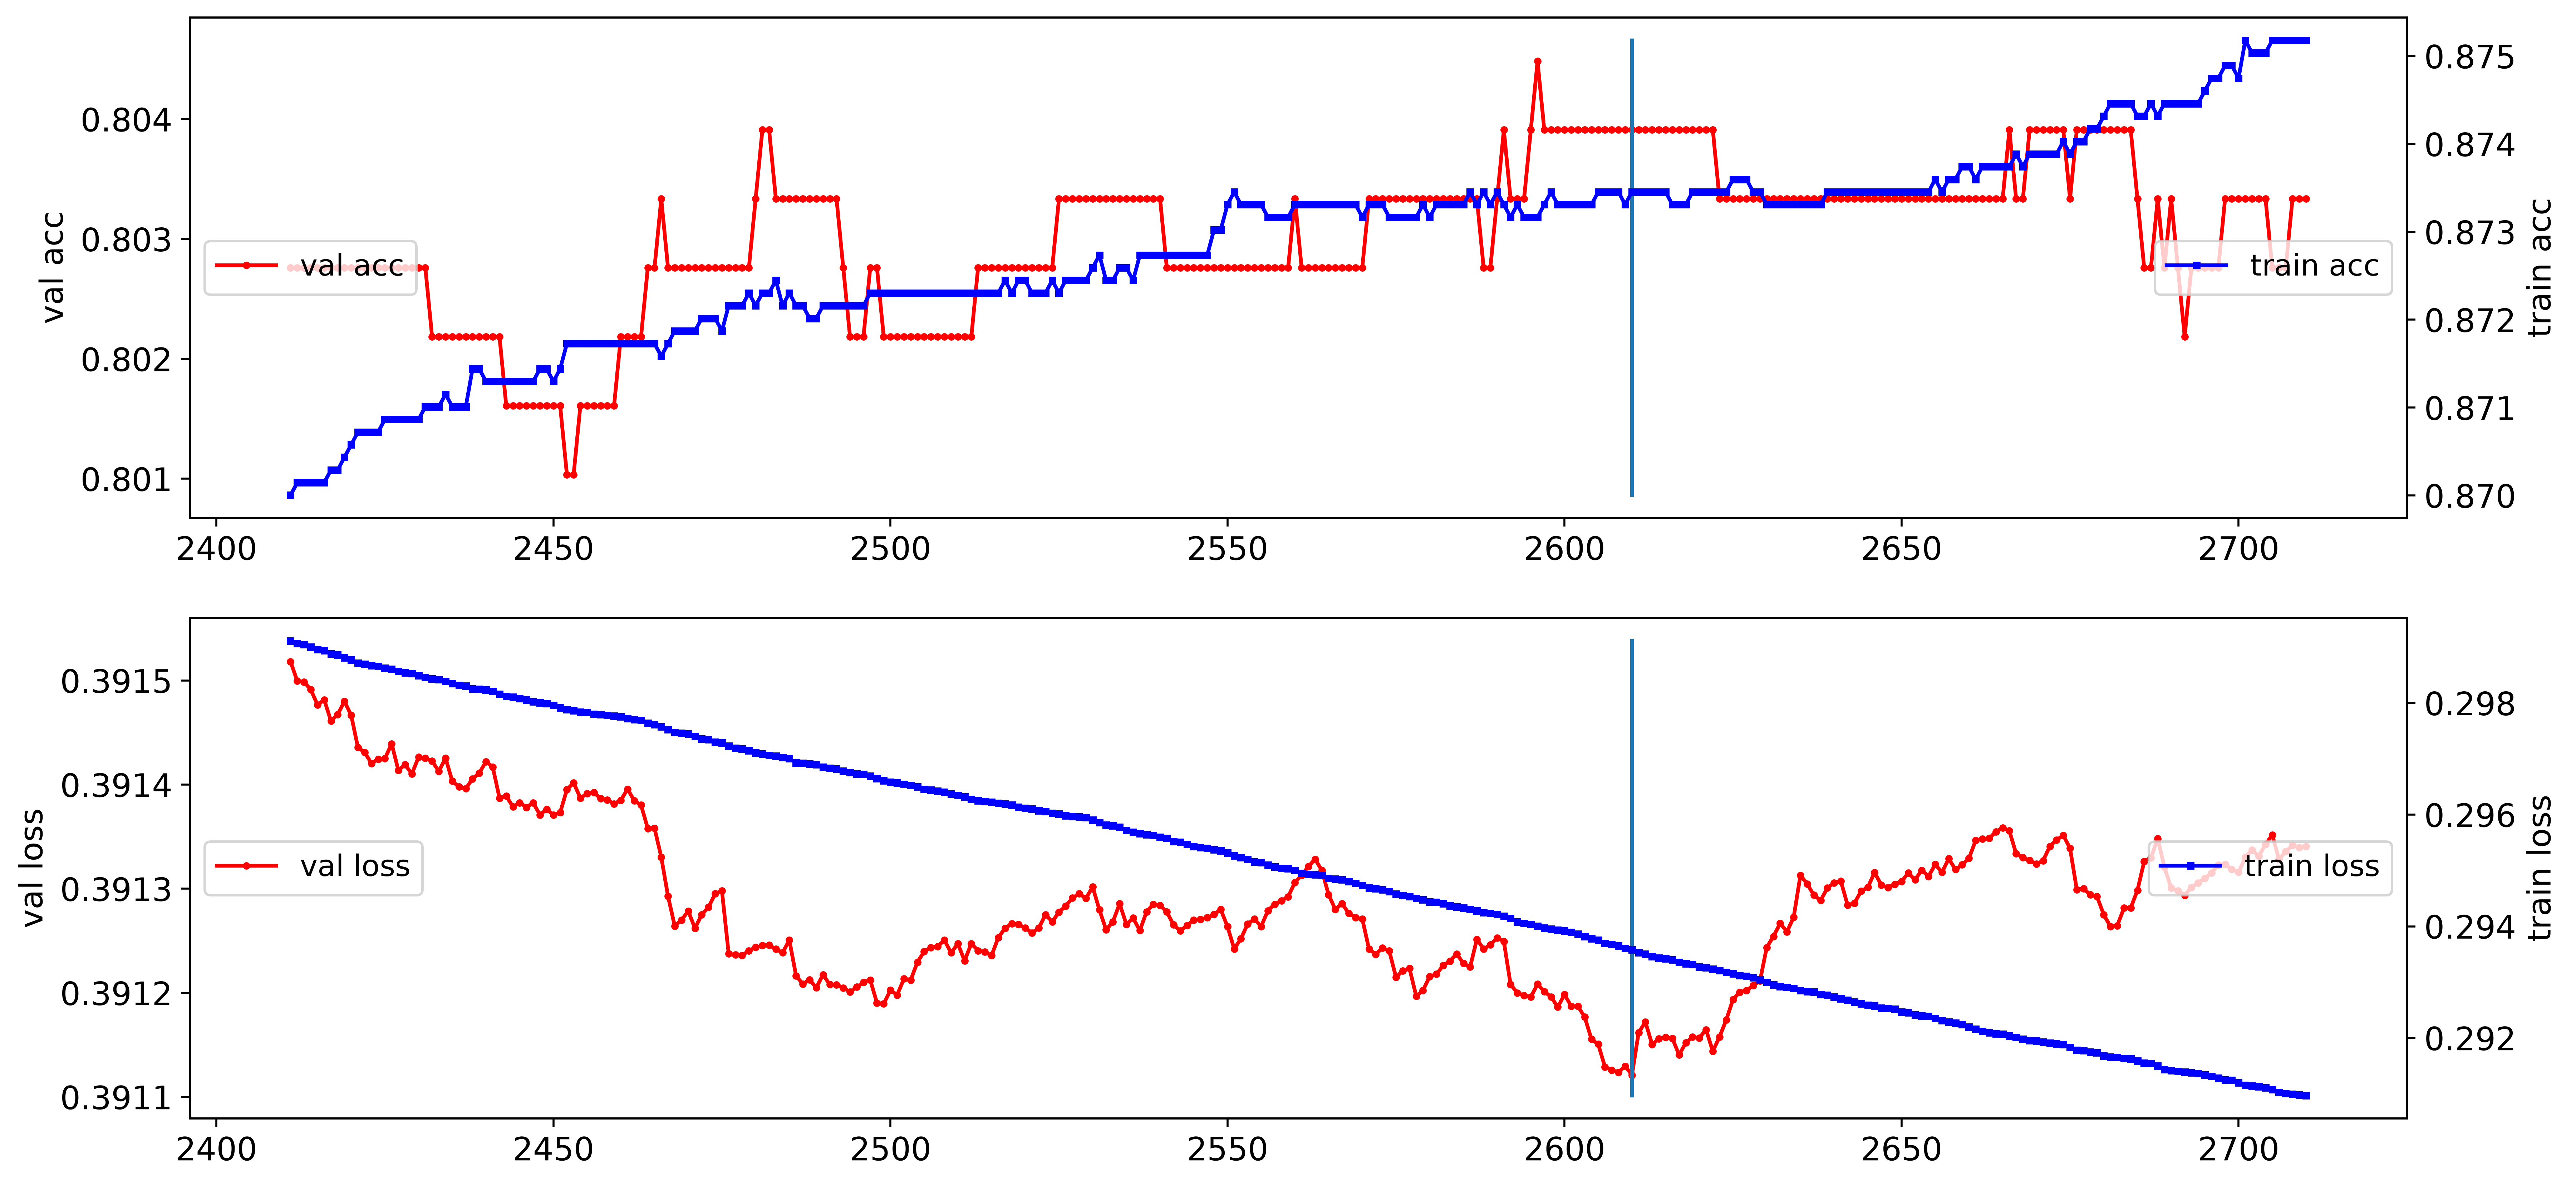

In [94]:
fig, ax = plt.subplots(nrows=2, dpi=500, figsize=(16, 8))

start_k = -300

ax[0].plot(val_score_list[start_k:, 0], val_score_list[start_k:, 1], marker='o', color='r', markersize=2, label='val acc')
ax[0].plot([best_iteration] * 100, np.linspace(*ax[0].get_ylim(), 100))
ax[0].set_ylabel('val acc')
ax[0].legend(loc='center left')

axr = ax[0].twinx()
axr.plot(train_score_list[start_k:, 0], train_score_list[start_k:, 1], marker='s', color='b', markersize=2, label='train acc')
axr.set_ylabel('train acc')
axr.legend(loc='center right')


axr = ax[1].twinx()
ax[1].plot(val_loss[start_k:, 0], val_loss[start_k:, 1], marker='o', color='r', markersize=2, label='val loss')
ax[1].set_ylabel('val loss')
ax[1].legend(loc='center left')
ax[1].plot([best_iteration] * 100, np.linspace(*ax[1].get_ylim(), 100))
axr.plot(train_loss[start_k:, 0], train_loss[start_k:, 1], marker='s', color='b', markersize=2, label='train loss')
axr.set_ylabel('train loss')
axr.legend(loc='center right')

In [95]:
test = pd.read_csv(path + "/test.csv")
sample = pd.read_csv(path + "/sample_submission.csv")

test_df = getData(test, istest=True)
test_df = test_df.reindex(
    columns=dataset_x.columns,
    fill_value=0
)

X_test = np.asarray(test_df, dtype=np.float32)
test_pred = xgboost.predict(X_test).astype(bool)

submit = sample.copy()
submit["Transported"] = test_pred

In [96]:
submit.to_csv(f'./data/submit_{datetime.now().isoformat()}.csv', index=False)
submit.to_csv(f'./submit.csv', index=False)